In [1]:
import sys
import numpy as np
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import rankdata, norm
from scipy.spatial.distance import pdist
from scipy.optimize import minimize
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C

# ---------------------------------------------------------------------
# 0. Reproducibility setup
# ---------------------------------------------------------------------
SEED = 42                                                 # Random seed  

print("=" * 70)
print("Software and Libraries used")
print("=" * 70)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ---------------------------------------------------------------------
# 1. Data
# ---------------------------------------------------------------------
X = np.load('..\Function_1_Data\Week_9_Data/F1_Week_9_inputs.npy')
y = np.load('..\Function_1_Data\Week_9_Data/F1_Week_9_outputs.npy')
n, d = X.shape
bounds = np.array([[0.0, 1.0], [0.0, 1.0]])
X_new = X
y_new = y
X_old = X[:-1]
y_old = y[:-1]
# X.shape, X, X_old, y, y_old

In [8]:
prev_best_idx = np.argmax(y_old)
prev_best_x, prev_best_y = X_old[prev_best_idx], y_old[prev_best_idx]
print(f"  Previous incumbent: x={prev_best_x}, y={prev_best_y:.3e}")
new_best_idx = np.argmax(y)
print(f"  New overall incumbent: x={X[new_best_idx]}, y={y[new_best_idx]:.6e}")

  Previous incumbent: x=[0.552105 0.538965], y=4.175e-10
  New overall incumbent: x=[0.552105 0.538965], y=4.175390e-10


In [22]:
# ---------------------------------------------------------------------
# 2. Re-apply rank-based copula transform to all 18 points
# ---------------------------------------------------------------------
def copula_transform(y):
    n = len(y)
    ranks = rankdata(y, method="average")
    quantiles = (ranks - 0.5) / n
    return norm.ppf(quantiles)

y_train = copula_transform(y)

print("=" * 100)
print("COPULA TRANSFORM CHECK")
print("=" * 100)
order = np.argsort(-np.abs(y))
ranks_all = rankdata(y, method="average")
print(f"\n  Range of y (raw)   : [{y.min():.3e}, {y.max():.3e}]")
print(f"  Dynamic range      : ~{np.log10(np.abs(y).max())-np.log10(np.abs(y[np.abs(y)>0]).min()):.0f} orders of magnitude")
print(f"  Ties in rank?  : {len(np.unique(ranks_all)) != n}")
print()


COPULA TRANSFORM CHECK

  Range of y (raw)   : [-3.606e-03, 4.175e-10]
  Dynamic range      : ~196 orders of magnitude
  Ties in rank?  : False



In [13]:
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

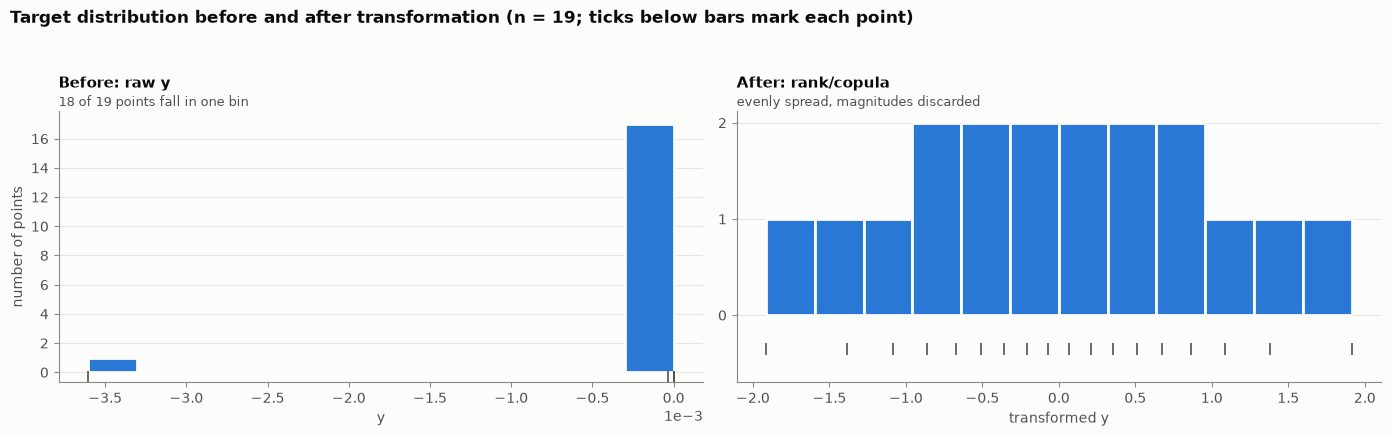

In [ ]:
# ------------------------------------------------ 
# Target distribution before and after transformation
# ------------------------------------------------ 
copula = norm.ppf((rankdata(y) - 0.5) / n)
panels = [
    ("Before: raw y", "18 of 19 points fall in one bin", y, "y"),
    ("After: rank/copula", "evenly spread, magnitudes discarded", copula, "transformed y"),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, (title, sub, v, xl) in zip(axes, panels):
    ax.hist(v, bins=12, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(v, np.full(n, -0.35), "|", color=INK2, markersize=9, markeredgewidth=1.2, clip_on=False)
    ax.set_title(f"{title}\n", pad=4)
    ax.text(0, 1.02, sub, transform=ax.transAxes, color=INK2, fontsize=9)
    ax.set_xlabel(xl)
    ax.set_ylim(bottom=-0.7)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
axes[0].set_ylabel("number of points")
axes[0].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
fig.suptitle("Target distribution before and after transformation (n = 19; ticks below bars mark each point)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("dist_before_after.png", dpi=140)

In [ ]:
# ---------------------------------------------------------------------
# Refit Matern 5/2 ARD GP on all 18 points
# ---------------------------------------------------------------------
def fit_surrogate(X, y_train, seed):
    d = X.shape[1]
    init_length_scales = np.array([np.median(pdist(X[:, [j]])) for j in range(d)])
    length_scale_bounds = (0.02, 2.0)
    kernel = C(1.0, (1e-2, 1e2)) * Matern(
        length_scale=init_length_scales,
        length_scale_bounds=length_scale_bounds,
        nu=2.5,
    )
    gp = GaussianProcessRegressor(
        kernel=kernel, alpha=1e-6, normalize_y=False,
        n_restarts_optimizer=15, random_state=seed,
    )
    gp.fit(X, y_train)
    return gp, init_length_scales

gp_new, init_ls_new = fit_surrogate(X, y_train, seed=SEED)

# For direct comparison, refit the OLD (n=17) GP with the same recipe
y_train_old = copula_transform(y_old)
gp_old, init_ls_old = fit_surrogate(X_old, y_train_old, seed=SEED)

print("=" * 100)
print("SURROGATE REFIT: n=17 (old) vs n=18 (new)")
print("=" * 100)
ls_old = gp_old.kernel_.k2.length_scale
ls_new = gp_new.kernel_.k2.length_scale
amp_old = np.sqrt(gp_old.kernel_.k1.constant_value)
amp_new = np.sqrt(gp_new.kernel_.k1.constant_value)
print(f"  n=17 kernel: {gp_old.kernel_}")
print(f"  n=18 kernel: {gp_new.kernel_}")
print()
print(f"  {'':>18}{'n=17 (old)':>14}{'n=18 (new)':>14}{'change':>12}")
print(f"  {'length-scale x1':>18}{ls_old[0]:14.4f}{ls_new[0]:14.4f}{ls_new[0]-ls_old[0]:12.4f}")
print(f"  {'length-scale x2':>18}{ls_old[1]:14.4f}{ls_new[1]:14.4f}{ls_new[1]-ls_old[1]:12.4f}")
print(f"  {'amplitude':>18}{amp_old:14.4f}{amp_new:14.4f}{amp_new-amp_old:12.4f}")
f_best_old = y_train_old.max()
f_best_new = y_train.max()
print(f"  {'f_best (copula)':>18}{f_best_old:14.4f}{f_best_new:14.4f}{f_best_new-f_best_old:12.4f}")
print()


SURROGATE REFIT: n=17 (old) vs n=18 (new)
  n=17 kernel: 0.934**2 * Matern(length_scale=[0.339, 0.0296], nu=2.5)
  n=18 kernel: 0.941**2 * Matern(length_scale=[0.0363, 0.02], nu=2.5)

                        n=17 (old)    n=18 (new)      change
     length-scale x1        0.3386        0.0363     -0.3022
     length-scale x2        0.0296        0.0200     -0.0096
           amplitude        0.9340        0.9410      0.0070
     f_best (copula)        1.8895        1.9145      0.0250



c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified lower bound 0.02. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [ ]:
# ---------------------------------------------------------------------
# 3b. sklearn flagged the fitted x2 length-scale as sitting right at the
#     lower bound (0.02) -- test whether loosening the bound changes the
#     answer.
# ---------------------------------------------------------------------
def fit_surrogate_custom_bounds(X, y_train, seed, ls_bounds):
    d = X.shape[1]
    init_length_scales = np.array([np.median(pdist(X[:, [j]])) for j in range(d)])
    kernel = C(1.0, (1e-2, 1e2)) * Matern(
        length_scale=init_length_scales, length_scale_bounds=ls_bounds, nu=2.5,
    )
    gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, normalize_y=False,
                                   n_restarts_optimizer=15, random_state=seed)
    gp.fit(X, y_train)
    return gp

print("=" * 100)
print("3b. LOWER-BOUND SENSITIVITY CHECK (n=18)")
print("=" * 100)
for lb in [0.02, 0.01, 0.005, 0.002]:
    gp_test = fit_surrogate_custom_bounds(X, y_train, SEED, (lb, 2.0))
    ls_test = gp_test.kernel_.k2.length_scale
    lml = gp_test.log_marginal_likelihood(gp_test.kernel_.theta)
    print(f"  lower_bound={lb:<6} -> length_scale=[{ls_test[0]:.4f}, {ls_test[1]:.4f}]  LML={lml:.3f}")
print()

3b. LOWER-BOUND SENSITIVITY CHECK (n=18)
  lower_bound=0.02   -> length_scale=[0.0363, 0.0200]  LML=-24.265


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified lower bound 0.02. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  lower_bound=0.01   -> length_scale=[0.0367, 0.0193]  LML=-24.264
  lower_bound=0.005  -> length_scale=[0.0367, 0.0193]  LML=-24.264
  lower_bound=0.002  -> length_scale=[0.5539, 0.0020]  LML=-24.011



c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified lower bound 0.002. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [19]:
# ---------------------------------------------------------------------
# Acquisition functions + next point (using the n=18 GP, bounds=(0.02,2.0))
# ---------------------------------------------------------------------
def expected_improvement(x, gp, f_best, xi=0.01):
    x = np.atleast_2d(x)
    mu, sigma = gp.predict(x, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    improvement = mu - f_best - xi
    z = improvement / sigma
    ei = improvement * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

def gp_ucb(x, gp, beta=2.0):
    x = np.atleast_2d(x)
    mu, sigma = gp.predict(x, return_std=True)
    return mu + np.sqrt(beta) * sigma

def next_point(acq_fn, gp, bounds, rng, n_restarts=25, **acq_kwargs):
    dim = bounds.shape[0]
    def neg_acq(x):
        return -acq_fn(x.reshape(1, -1), gp, **acq_kwargs)[0]
    best_x, best_val = None, np.inf
    starts = rng.uniform(bounds[:, 0], bounds[:, 1], size=(n_restarts, dim))
    for x0 in starts:
        res = minimize(neg_acq, x0=x0, bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun; best_x = res.x
    return best_x, -best_val

rng = np.random.default_rng(SEED)
f_best = y_train.max()

print("=" * 100)
print("4. NEXT POINT PROPOSALS (n=18 model)")
print("=" * 100)
for xi_test in [0.01, 0.1, 0.5]:
    x_prop, val = next_point(expected_improvement, gp_new, bounds, rng=rng, f_best=f_best, xi=xi_test)
    print(f"  EI  xi={xi_test:<5} -> next point {np.round(x_prop, 6)}  (EI={val:.4f})")
print()
for beta_test in [4.0, 9.0, 16.0]:
    x_prop, val = next_point(gp_ucb, gp_new, bounds, rng=rng, beta=beta_test)
    print(f"  UCB beta={beta_test:<5} -> next point {np.round(x_prop, 4)}  (UCB={val:.4f})")
print()


4. NEXT POINT PROPOSALS (n=18 model)
  EI  xi=0.01  -> next point [0.532718 0.540371]  (EI=0.1555)
  EI  xi=0.1   -> next point [0.530949 0.540495]  (EI=0.1222)
  EI  xi=0.5   -> next point [0.52573  0.541336]  (EI=0.0373)

  UCB beta=4.0   -> next point [0.5238 0.5422]  (UCB=2.9399)
  UCB beta=9.0   -> next point [0.5204 0.547 ]  (UCB=3.6308)
  UCB beta=16.0  -> next point [0.5185 0.5523]  (UCB=4.3969)



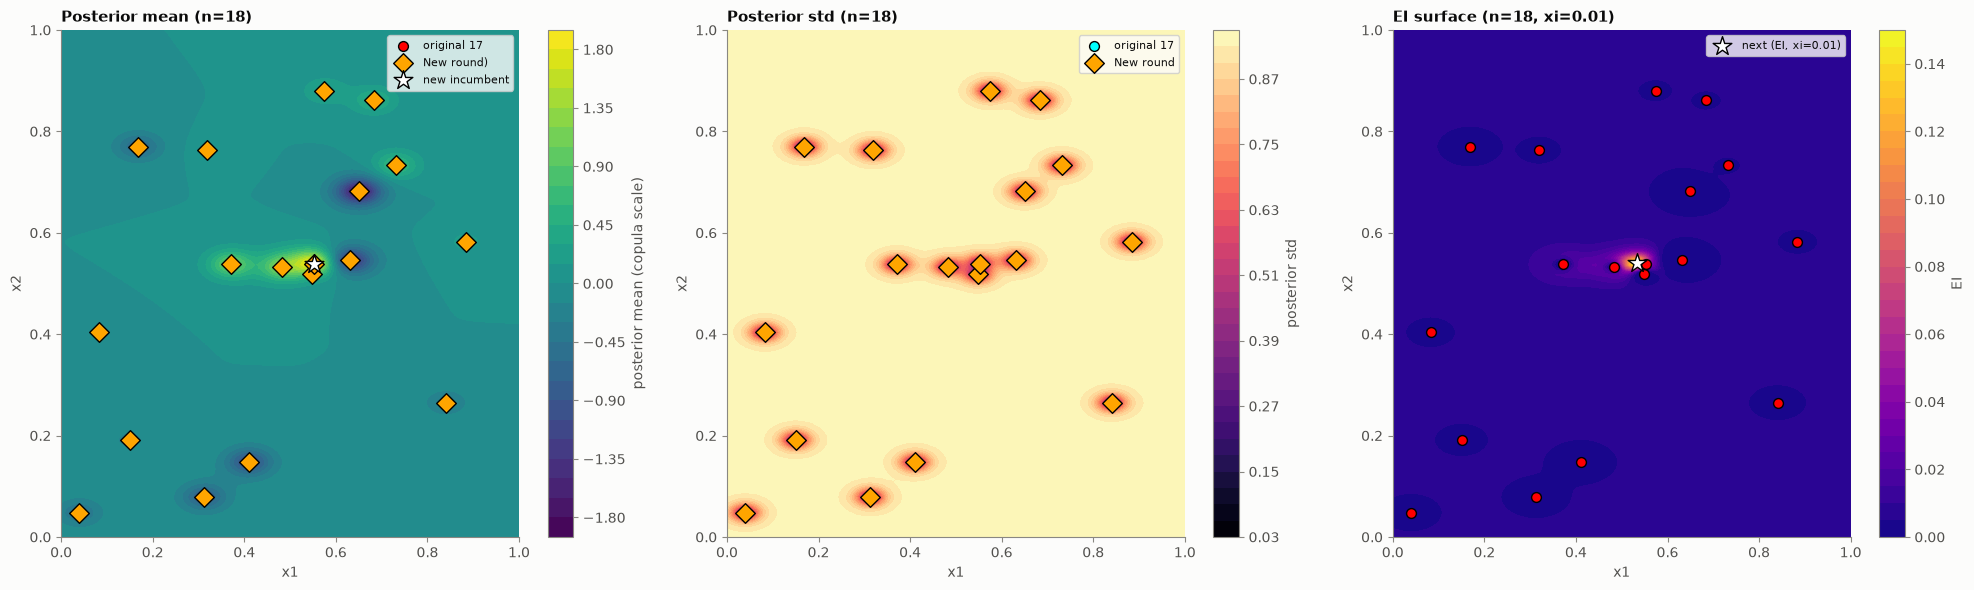

In [21]:

# ---------------------------------------------------------------------
# Plot: posterior mean/std comparison old vs new, + EI surface
# ---------------------------------------------------------------------
grid_n = 150
gx = np.linspace(0, 1, grid_n); gy = np.linspace(0, 1, grid_n)
GX, GY = np.meshgrid(gx, gy)
grid_points = np.column_stack([GX.ravel(), GY.ravel()])

mean_new, std_new = gp_new.predict(grid_points, return_std=True)
mean_new = mean_new.reshape(grid_n, grid_n); std_new = std_new.reshape(grid_n, grid_n)
EI_grid = expected_improvement(grid_points, gp_new, f_best=f_best, xi=0.01).reshape(grid_n, grid_n)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
ax = axes[0]
cf = ax.contourf(GX, GY, mean_new, levels=30, cmap="viridis")
ax.scatter(X_old[:,0], X_old[:,1], c="red", edgecolor="k", s=50, label="original 17")
ax.scatter(X_new[:,0], X_new[:,1], c="orange", edgecolor="k", s=100, marker="D", label="New round)")
ax.scatter(*X[new_best_idx], c="white", edgecolor="black", s=200, marker="*", label="new incumbent")
plt.colorbar(cf, ax=ax, label="posterior mean (copula scale)")
ax.set_title("Posterior mean (n=18)"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8)

ax = axes[1]
cf2 = ax.contourf(GX, GY, std_new, levels=30, cmap="magma")
ax.scatter(X_old[:,0], X_old[:,1], c="cyan", edgecolor="k", s=50, label="original 17")
ax.scatter(X_new[:,0], X_new[:,1], c="orange", edgecolor="k", s=100, marker="D", label="New round")
plt.colorbar(cf2, ax=ax, label="posterior std")
ax.set_title("Posterior std (n=18)"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8)

ax = axes[2]
cf3 = ax.contourf(GX, GY, EI_grid, levels=30, cmap="plasma")
ax.scatter(X[:,0], X[:,1], c="red", edgecolor="k", s=50)
next_x_ei, _ = next_point(expected_improvement, gp_new, bounds, rng=np.random.default_rng(SEED), f_best=f_best, xi=0.01)
ax.scatter(*next_x_ei, c="white", edgecolor="black", s=200, marker="*", label="next (EI, xi=0.01)")
plt.colorbar(cf3, ax=ax, label="EI")
ax.set_title("EI surface (n=18, xi=0.01)"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

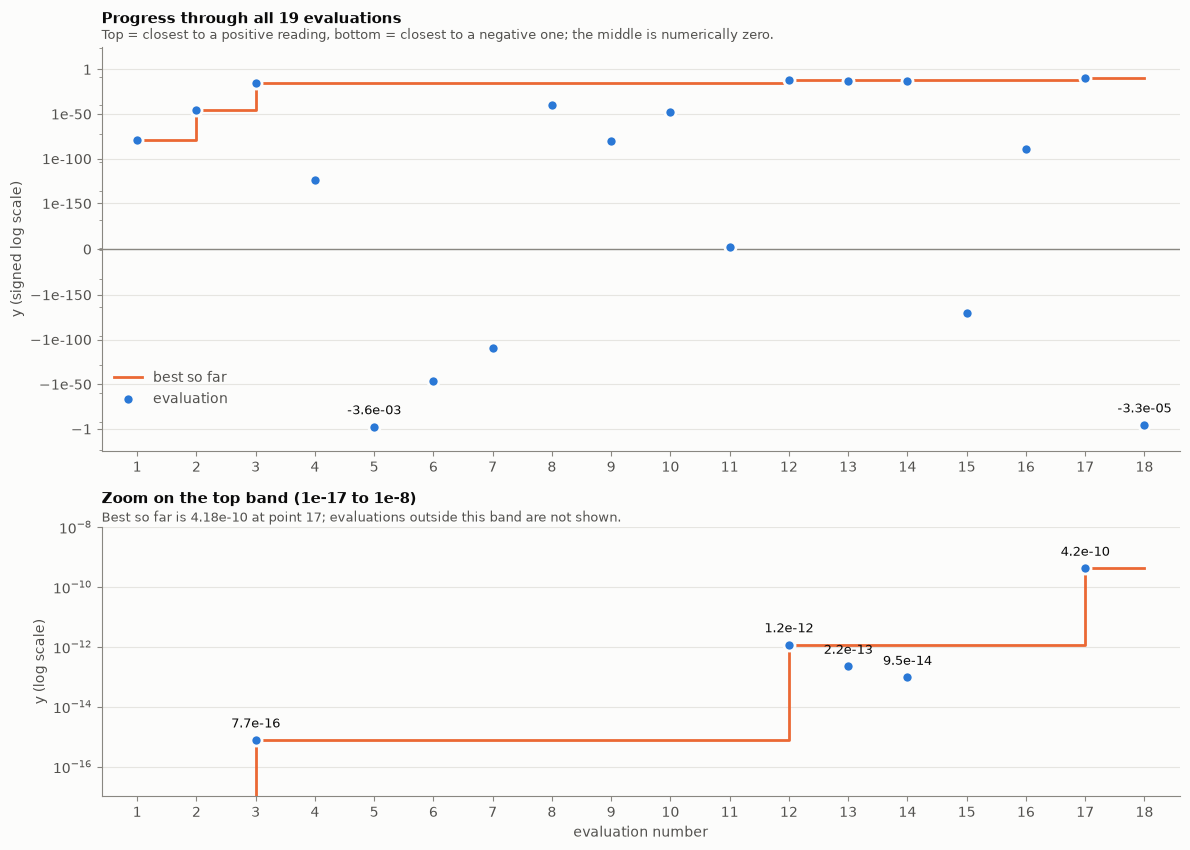

In [ ]:
# ------------------------------------------------ 
# Progress through all points
# ------------------------------------------------ 

idx = np.arange(1, n + 1)
best = np.maximum.accumulate(y)
inc = int(np.argmax(y))
fig, (ax, az) = plt.subplots(2, 1, figsize=(12, 8.6), height_ratios=[3, 2])
ax.axhline(0, color=MUTED, linewidth=1)
ax.step(idx, best, where="post", color=ORANGE, linewidth=2, label="best so far", zorder=2)
ax.scatter(idx, y, s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, label="evaluation", zorder=3)
ax.set_yscale("symlog", linthresh=1e-200)
ticks = [-1e0, -1e-50, -1e-100, -1e-150, 0, 1e-150, 1e-100, 1e-50, 1e0]
ax.set_yticks(ticks)
ax.set_yticklabels(["−1", "−1e-50", "−1e-100", "−1e-150", "0", "1e-150", "1e-100", "1e-50", "1"])
ax.set_ylim(-1e25, 1e25)
ax.set_ylabel("y (signed log scale)")
for i in (4, 17):
    ax.annotate(f"{y[i]:.1e}", (idx[i], y[i]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 0.08), labelcolor=INK2)
ax.set_title("Progress through all 19 evaluations\n", pad=4)
ax.text(0, 1.02, "Top = closest to a positive reading, bottom = closest to a negative one; "
        "the middle is numerically zero.", transform=ax.transAxes, color=INK2, fontsize=9)

lo, hi = 1e-17, 1e-8
m = (y > lo) & (y < hi)
az.step(idx, best, where="post", color=ORANGE, linewidth=2, zorder=2)
az.scatter(idx[m], y[m], s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
az.set_yscale("log")
az.set_ylim(lo, hi)
for i in np.where(m)[0]:
    az.annotate(f"{y[i]:.1e}", (idx[i], y[i]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
az.set_ylabel("y (log scale)")
az.set_xlabel("evaluation number")
az.set_title("Zoom on the top band (1e-17 to 1e-8)\n", pad=4)
az.text(0, 1.02, f"Best so far is {y[inc]:.2e} at point {inc + 1}; evaluations outside this band are not shown.",
        transform=az.transAxes, color=INK2, fontsize=9)
for a_ in (ax, az):
    a_.set_xticks(idx)
    a_.set_xlim(0.4, n + 0.6)
    a_.grid(axis="x", visible=False)
fig.tight_layout()
